In [62]:
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
import simulate_CCE_Li_plot_path as sim
import argparse
import numpy as np

In [10]:
sim.Lx = 0.1  # 1 mm
sim.Ly = 0.2  # 2 mm
sim.Lz = 0.2  # 2 mm

sim.args.FCCD = 0.1
FCCD = 0.1
sim.args.seed = 1

np.random.seed(sim.args.seed)

params = sim.update_parameters(sim.args)

In [112]:
my_args = argparse.Namespace(        
            seed=int(1),        
            N_charges=125,        
            N_repeat=125,        
            alpha=1e-8,     
            FCCD = 0.085,   
            sigma_R = 0.006,
            N_min_agg = 5,
            T_ann=623,        
            t_ann=18*60,        
            output="library"
        )
params = sim.update_parameters(my_args)

In [113]:
cells, saturation_depth, px, py, pz, particles_R, lithium_distribution = sim.generate_lithium(params)

Calculating Li concentration: 100%|██████████| 66/66 [00:00<00:00, 16460.97it/s]


0.006 um



Generating Li agglomerates: 100%|██████████| 66/66 [00:10<00:00,  6.38it/s]


Total theoretical primary Li (R=20 um) = 40023
Total theoretical agglomerates = 3698
Total theoretical remaining 20 um particles = 983
Total accepted agglomerates = 3408
Total accepted remaining 20 um particles = 983
Total accepted Li particles = 4391


In [118]:
collected_path, lost_path = sim.find_example_paths(
    x0=0.06,
    particle_x=px,
    particle_y=py,
    particle_z=pz,
    particle_R=particles_R,
    saturation_depth=saturation_depth,
    FCCD=0.1,
    max_trials=100000
)

In [119]:

print("Lacuna raccolta:", collected_path["status"])
print("Lacuna persa:", lost_path["status"])

Lacuna raccolta: collected
Lacuna persa: lithium_trap


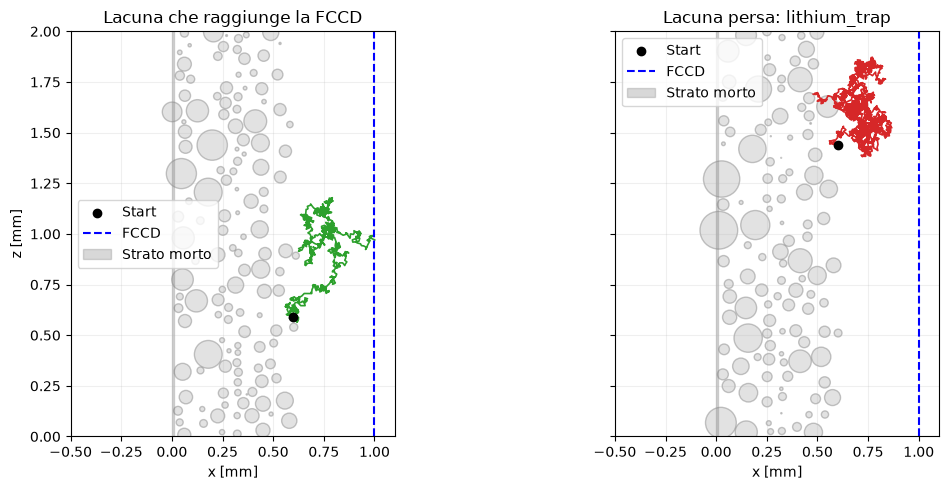

In [120]:
sim.plot_xz_paths(
    collected_path=collected_path,
    lost_path=lost_path,
    particle_x=px,
    particle_y=py,
    particle_z=pz,
    particle_R=particles_R,
    FCCD=0.1
)

--------------------------------
CCE simulation
--------------------------------
seed = 1
--------------------------------


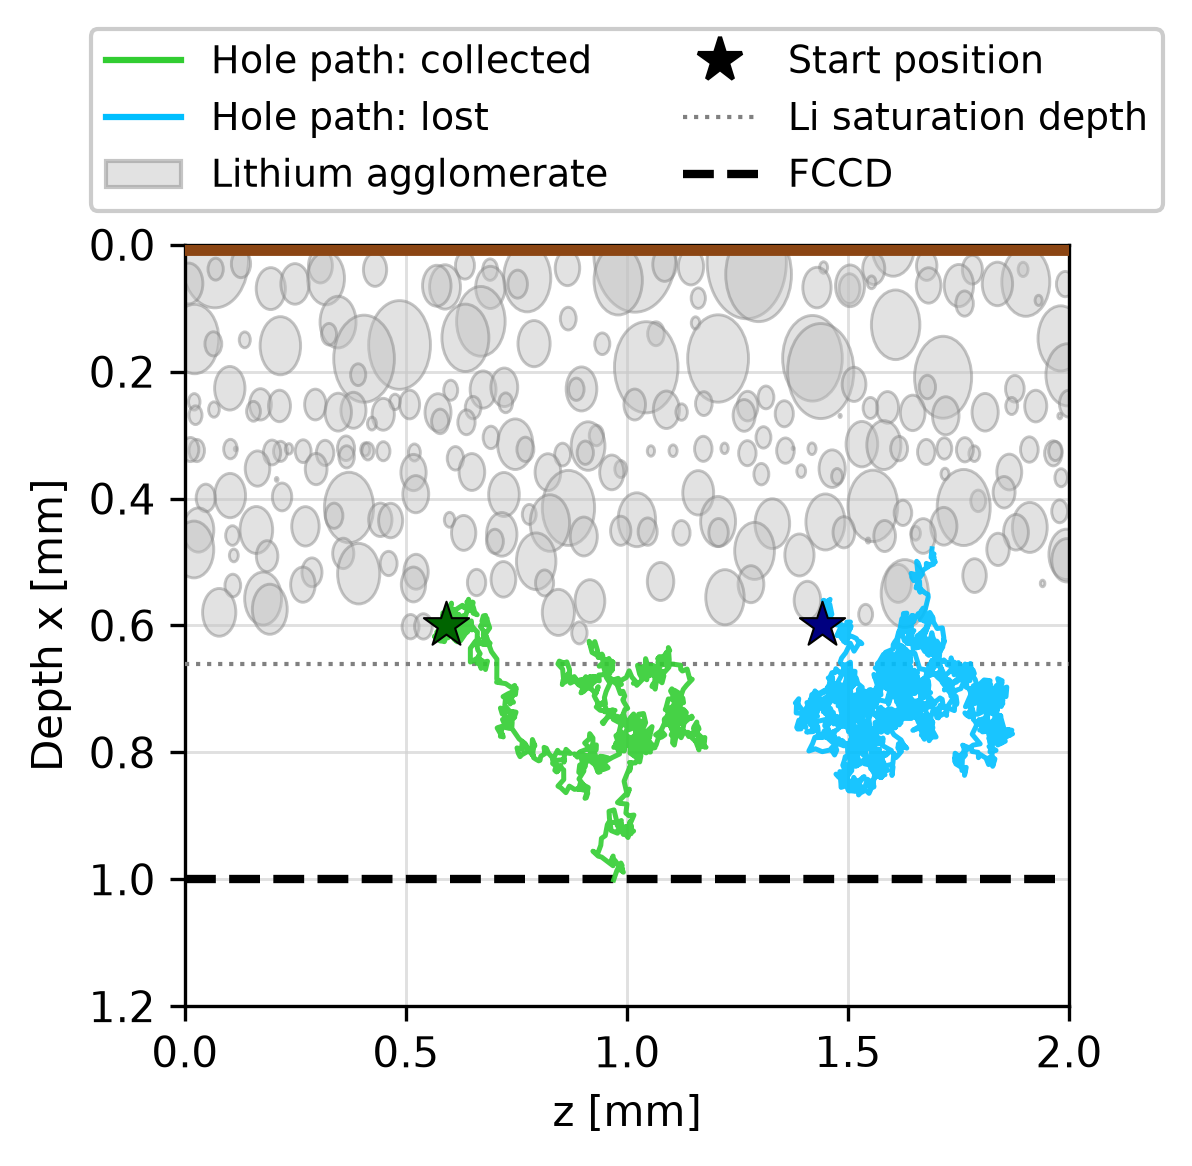

In [121]:
import importlib
importlib.reload(sim)




sim.plot_hole_paths2(
    params = params ,
    collected_path=collected_path,
    lost_path=lost_path,
    particle_x=px,
    particle_y=py,
    particle_z=pz,
    particle_R=particles_R,
    FCCD=0.9
)